# Exploratory data analysis

Goals:
- understand each variable: type, domain, distribution, missing values
- feed the fundamental analysis in `00_framing` (What, Who, When, Where, How, Why, red flags);
- study the target and its relationships with the features.

## 1. Setup

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind

In [96]:
train = pd.read_csv("../data/train_data.csv")
test = pd.read_csv("../data/test_data.csv")

In [97]:
def churn_by_category(df, col, target="Exited"):
    """Distribution of a categorical variable, churn rate per category,
    chi-square test of independence and Cramér's V."""
    print("Distribution:")
    print(df[col].value_counts(normalize=True).sort_index().round(3))

    rate = pd.crosstab(df[col], df[target], normalize="index")[1]
    print("\nChurn rate:")
    print(rate.round(3))

    counts = pd.crosstab(df[col], df[target])
    result = chi2_contingency(counts)
    n = counts.values.sum()
    k = min(counts.shape)
    cramers_v = np.sqrt(result.statistic / (n * (k - 1)))
    print(f"\nchi2 p-value: {result.pvalue:.3g} | min expected count: {result.expected_freq.min():.0f} | Cramér's V: {cramers_v:.3f}")

    overall = df[target].mean()
    rate.plot(kind="bar")
    plt.axhline(overall, color="red", linestyle="--", label=f"overall churn rate ({overall:.0%})")
    plt.ylabel("churn rate")
    plt.title(f"Churn rate by {col}")
    plt.legend()
    plt.show()

## 2. Overview

In [98]:
print (f"train data shape: {train.shape}")
print (f"test data shape: {test.shape}")

train data shape: (143579, 14)
test data shape: (21455, 13)


In [99]:
train.head()

,ID,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,37765,15794860,Ch'eng,627,France,Male,28.0,7,131694.04,1,1.0,1.0,161205.61,0
1,130453,15728005,Hargreaves,597,France,Male,34.0,2,0.00,2,0.0,1.0,181419.29,0
2,77297,15686810,Ts'ui,724,France,Male,39.0,7,0.00,2,1.0,1.0,100862.54,0
3,40858,15760244,Trevisano,663,Germany,Female,56.0,5,118577.24,3,1.0,0.0,61164.45,1
4,19804,15810563,French,627,France,Female,33.0,5,0.00,2,1.0,1.0,103737.82,0


In [100]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 143579 entries, 0 to 143578
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   ID               143579 non-null  int64  
 1   CustomerId       143579 non-null  int64  
 2   Surname          143579 non-null  str    
 3   CreditScore      143579 non-null  int64  
 4   Geography        143579 non-null  str    
 5   Gender           143579 non-null  str    
 6   Age              143579 non-null  float64
 7   Tenure           143579 non-null  int64  
 8   Balance          143579 non-null  float64
 9   NumOfProducts    143579 non-null  int64  
 10  HasCrCard        143579 non-null  float64
 11  IsActiveMember   143579 non-null  float64
 12  EstimatedSalary  143579 non-null  float64
 13  Exited           143579 non-null  int64  
dtypes: float64(5), int64(6), str(3)
memory usage: 15.3 MB


In [101]:
summary = pd.DataFrame({
    "dtype": train.dtypes,
    "n_unique": train.nunique(),
    "min": train.min(numeric_only=True),
    "max": train.max(numeric_only=True),
})
summary

,dtype,n_unique,min,max
Age,float64,71,18.00,92.00
Balance,float64,27258,0.00,250898.09
CreditScore,int64,456,350.00,850.00
CustomerId,int64,22017,15565701.00,15815690.00
EstimatedSalary,float64,50076,11.58,199992.48
Exited,int64,2,0.00,1.00
Gender,str,2,NaN,NaN
Geography,str,3,NaN,NaN
HasCrCard,float64,2,0.00,1.00
ID,int64,143579,0.00,165033.00


**Variable types**
- Identifiers (not features): `ID`, `CustomerId`
- Categorical / discrete: `Surname`, `Geography`, `Gender`, `NumOfProducts`, `Tenure`, `HasCrCard`, `IsActiveMember`
- Continuous: `CreditScore`, `Age`, `Balance`, `EstimatedSalary`
- Target: `Exited` (binary)

In [102]:
train.isna().sum()

ID                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

No missing values in any column.

## 3. Target

In [103]:
train["Exited"].value_counts(normalize=True)

Exited
0    0.787922
1    0.212078
Name: proportion, dtype: float64

<Axes: xlabel='Exited'>

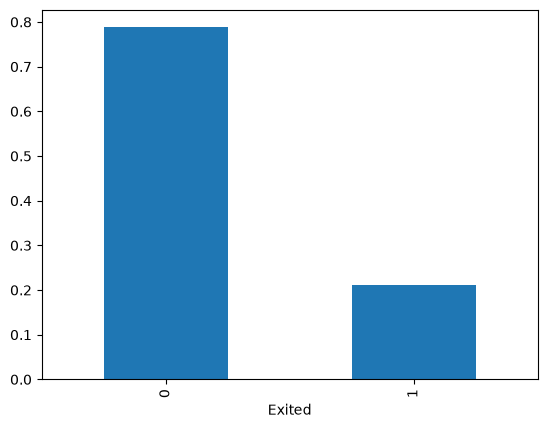

In [104]:
train["Exited"].value_counts(normalize=True).plot(kind="bar")

`Exited` is binary and imbalanced: about 21% churn (1) vs 79% stay (0).

## 4. Data origin

I compare our data with the Kaggle Playground competition [S4E1](https://www.kaggle.com/competitions/playground-series-s4e1/data), whose data is documented as *"generated from a deep learning model trained on the Bank Customer Churn Prediction dataset"*.

In [105]:
import kagglehub

path = kagglehub.competition_download("playground-series-s4e1")
s4e1 = pd.read_csv(path + "/train.csv")

summary_s4e1 = pd.DataFrame({
    "dtype": s4e1.dtypes,
    "n_unique": s4e1.nunique(),
    "min": s4e1.min(numeric_only=True),
    "max": s4e1.max(numeric_only=True),
})
summary_s4e1

,dtype,n_unique,min,max
Age,float64,71,18.00,92.00
Balance,float64,30075,0.00,250898.09
CreditScore,int64,457,350.00,850.00
CustomerId,int64,23221,15565701.00,15815690.00
EstimatedSalary,float64,55298,11.58,199992.48
Exited,int64,2,0.00,1.00
Gender,str,2,NaN,NaN
Geography,str,3,NaN,NaN
HasCrCard,float64,2,0.00,1.00
IsActiveMember,float64,2,0.00,1.00


**Comparison with our data (section 2):**
- **Row count**: S4E1 train has 165,034 rows (`id` from 0 to 165,033). Our train + test = 143,579 + 21,455 = 165,034, and our `ID` also ranges from 0 to 165,033.
- **Unique values**: S4E1 always has slightly more unique values than our train (`CustomerId` 23,221 vs 22,017, `Surname` 2,797 vs 2,765, `Balance` 30,075 vs 27,258). This is consistent with our train being a subset of S4E1 (a subset cannot have more unique values), but it is not a proof.
- **Types**: same dtypes (e.g. `Age`, `HasCrCard`, `IsActiveMember` stored as float64 in both).
- **Ranges**: identical min and max for every numeric column, to the cent (e.g. `Balance` 0 to 250,898.09, `EstimatedSalary` 11.58 to 199,992.48, `Age` 18 to 92). A subset must stay within the ranges of the full set; here they are exactly the same.
- **Same artifacts**: `CustomerId` and `Surname` are not unique in S4E1 either.

These clues converge: our data is most likely a split of the S4E1 train set. **Next: verify it row by row** (merge on `ID` / `id`).

### Row-by-row check

For each row of our train, find the S4E1 row with the same identifier (`ID` = `id`) and compare every column.

In [106]:
merged = train.merge(
    s4e1, left_on="ID", right_on="id", how="left",
    suffixes=("_ours", "_s4e1"), indicator=True,
)
print("rows in our train:", len(train))
print("rows found in S4E1:", (merged["_merge"] == "both").sum())

# For each column, count the rows where our value differs from the S4E1 value
cols = [c for c in train.columns if c != "ID"]
differences = pd.Series(
    {c: (merged[f"{c}_ours"] != merged[f"{c}_s4e1"]).sum() for c in cols},
    name="rows with a different value",
)
differences

rows in our train: 143579
rows found in S4E1: 143579


CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
Name: rows with a different value, dtype: int64

**Conclusion:** all 143,579 rows of our train are found in the S4E1 train set, with **0 difference** in every column. Our train is an exact subset of S4E1 (observed). Our test (21,455 rows) most likely contains the remaining S4E1 rows (same total, not checked row by row).

Consequence: our data is **synthetic**, generated by a deep learning model trained on the original churn dataset (S4E1 documentation). The generator details (model, how `CustomerId` and `Surname` were assigned) are not documented.

## 5. CustomerId

An identifier should be unique, but there are only 22,017 unique values for 143,579 rows.

In [107]:
train["CustomerId"].value_counts(sort=True)

CustomerId
15682355    104
15570194     92
15585835     85
15595588     79
15585067     79
           ... 
15592494      1
15632987      1
15571053      1
15777224      1
15754930      1
Name: count, Length: 22017, dtype: int64

In [108]:
train[train["CustomerId"].isin([15682355, 15570194, 15585835])]

,ID,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
409,95668,15682355,Chienezie,775,France,Female,56.0,9,124049.80,4,0.0,1.0,163801.53,1
1475,136064,15585835,McLean,571,Spain,Male,35.0,3,0.00,2,1.0,0.0,129968.47,0
1549,86643,15585835,Castro,700,France,Female,40.0,10,176914.80,4,0.0,0.0,12799.23,1
1787,30243,15682355,Frewin,694,France,Female,57.0,9,0.00,1,1.0,0.0,64869.76,1
2095,96463,15570194,Ozerova,675,France,Female,45.0,7,56674.92,1,1.0,1.0,119374.56,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140182,69128,15570194,Hs?,712,France,Male,29.0,2,0.00,2,1.0,0.0,145560.37,0
140681,99086,15585835,P'eng,544,France,Male,38.0,2,0.00,2,1.0,0.0,167773.33,0
140867,152507,15570194,Nnamutaezinwa,628,Germany,Female,33.0,2,89025.09,2,1.0,1.0,51553.97,0
140872,61181,15682355,Chizuoke,678,Spain,Male,35.0,5,128131.73,1,1.0,1.0,101039.53,0


Rows sharing the same `CustomerId` have nothing in common (different surname, gender, country, age, tenure): **`CustomerId` is not a real customer identifier.**
Explanation: the whole dataset was generated by a deep learning model (S4E1 documentation, section 4). The generator produced `CustomerId` values like any other column, without linking them to a single person (how exactly is not documented).
Decision: not used as a feature.

## 6. Surname

In [109]:
train["Surname"].value_counts(sort=True)

Surname
Hsia       2107
T'ien      1971
Hs?        1387
Ts'ui      1364
Maclean    1364
           ... 
Utz           1
Lorimer       1
Belcher       1
Miranda       1
Walpole       1
Name: count, Length: 2765, dtype: int64

In [110]:
train[train["Surname"].isin(["Hsia", "T'ien", "Hs?"])]

,ID,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
30,122520,15691817,Hs?,850,France,Male,42.0,5,0.00,1,1.0,1.0,60917.24,0
42,11147,15793883,T'ien,678,France,Female,49.0,7,0.00,1,1.0,0.0,85890.68,1
55,111803,15688865,Hsia,644,Germany,Male,51.0,1,97910.71,1,1.0,0.0,126726.28,1
79,56441,15607837,Hsia,673,France,Female,51.0,4,0.00,2,0.0,1.0,139066.53,1
161,47060,15809654,Hsia,549,France,Female,40.0,8,127476.73,2,1.0,1.0,146011.55,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143413,74253,15752731,Hs?,632,France,Male,29.0,3,0.00,2,0.0,0.0,131712.52,0
143482,78778,15735837,Hsia,574,Spain,Male,38.0,3,0.00,2,1.0,1.0,8559.66,0
143522,12134,15590730,Hsia,814,Spain,Male,39.0,4,0.00,2,1.0,1.0,125877.69,0
143536,89141,15686885,Hs?,592,France,Male,30.0,3,0.00,2,1.0,0.0,157549.60,0


No common pattern among rows sharing a surname. Some surnames contain "?" (e.g. "Hs?"): non-ASCII characters were lost (encoding issue).

**Hypothesis to test:** if surnames were drawn at random **independently of the other columns**, each surname should follow the overall country split.

In [111]:
train["Geography"].value_counts(normalize=True)

Geography
France     0.570320
Spain      0.220004
Germany    0.209676
Name: proportion, dtype: float64

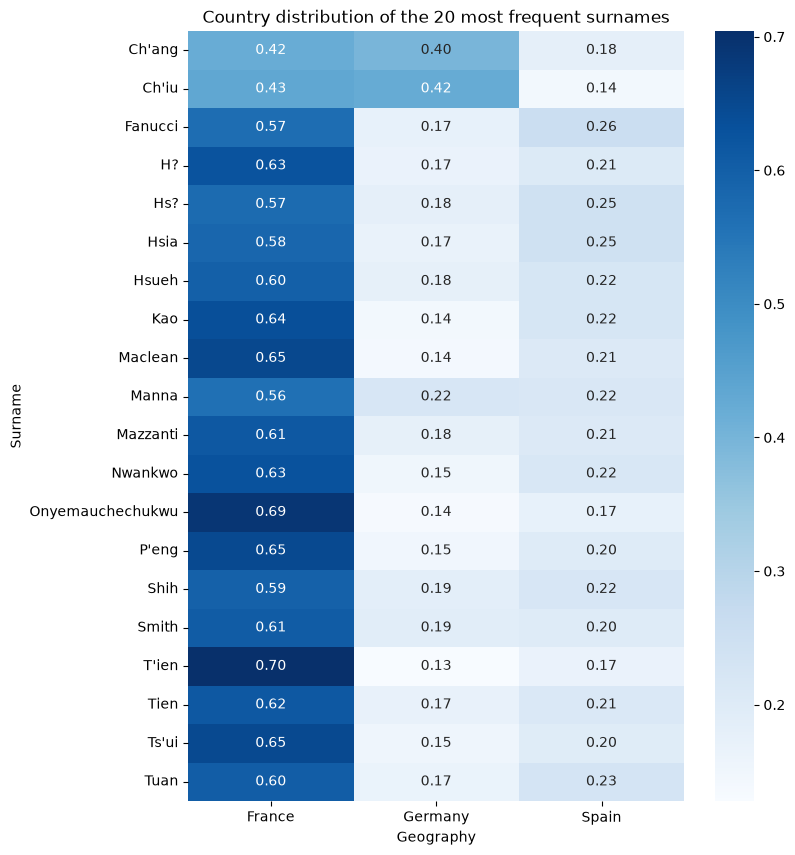

In [112]:
top_surnames = train["Surname"].value_counts().head(20).index
top = train[train["Surname"].isin(top_surnames)]
ct = pd.crosstab(top["Surname"], top["Geography"], normalize="index")

plt.figure(figsize=(8, 10))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues")
plt.title("Country distribution of the 20 most frequent surnames")
plt.show()

### χ² test of independence: Surname × Geography

- **H0:** `Surname` is independent of `Geography`. **α = 5%**, set before the test.
- **Condition:** at least 5 *expected* counts per cell. The smallest expected cell is Germany: n × 0.21 ≥ 5, so n ≥ 24. Surnames with fewer than 24 rows are excluded (filter on the total per surname, not on the per-country counts, to avoid biasing the test).

In [113]:
cross_tab = pd.crosstab(train["Surname"], train["Geography"])
cross_tab_frequent = cross_tab[cross_tab.sum(axis=1) >= 24]

result = chi2_contingency(cross_tab_frequent)
print("surnames kept:", len(cross_tab_frequent))
print("customers covered:", cross_tab_frequent.values.sum())
print("p-value:", result.pvalue)
print("min expected count:", result.expected_freq.min())

# Strength of the link : Cramér's V, between 0 (no link) and 1 (perfect link)
n = cross_tab_frequent.values.sum()
k = min(cross_tab_frequent.shape)
cramers_v = np.sqrt(result.statistic / (n * (k - 1)))
print("Cramér's V:", round(cramers_v, 3))

surnames kept: 778
customers covered: 128520
p-value: 0.0
min expected count: 5.049859943977591
Cramér's V: 0.19


**Conclusion**
- Condition met: minimum expected count = 5.05 ≥ 5.
- p < 0.001 < α: **H0 is rejected**. Among the 778 surnames with at least 24 rows (128,520 customers), surnames are not independent of country. This does not prove H1. Since the data was generated (section 4), the result means that the generator partially preserved the surname–country links of the original data.
- With 128,520 customers, even a small deviation gives a tiny p-value: the p-value shows that a link exists, not how strong it is. Strength : **Cramér's V ≈ 0.19**, a weak-to-moderate link (benchmarks for 3 categories: 0.07 weak, 0.21 moderate, 0.35 strong). Part of it is noise: with this many surnames, V would already be about 0.08 under H0. This is consistent with the heatmap: most surnames are close to the overall split, a few deviate clearly.
- This is consistent with surnames being generated partly at random and partly preserving links with other columns (the generator details are not documented).

**Decision:** `Surname` is not used as a feature, because it has no business meaning, it could act as a proxy for ethnic origin (ethical risk), and it has encoding issues. The test result is not the reason for this decision.

## 7. Geography

In [114]:
train["Geography"].value_counts(normalize=True)

Geography
France     0.570320
Spain      0.220004
Germany    0.209676
Name: proportion, dtype: float64

In [115]:
churn_by_country = pd.crosstab(train["Geography"], train["Exited"], normalize="index")[1]
churn_by_country

Geography
France     0.165450
Germany    0.380269
Spain      0.172661
Name: 1, dtype: float64

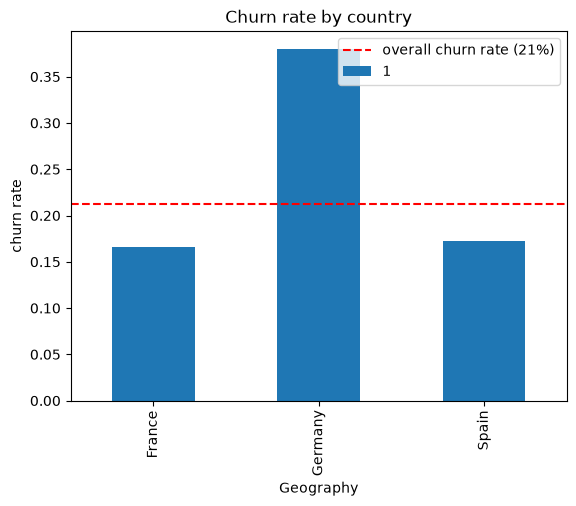

In [116]:
churn_by_country.plot(kind="bar")
plt.axhline(train["Exited"].mean(), color="red", linestyle="--", label="overall churn rate (21%)")
plt.ylabel("churn rate")
plt.title("Churn rate by country")
plt.legend()
plt.show()

**Observation:** churn rate is 16.5% in France, 17.3% in Spain and **38.0% in Germany**.
Germany is +21.5 points above France and +17 points above the overall rate (21%), i.e. about 2.3 times the French churn rate.

**Hypothesis:** churn depends on the country.
- H0: `Exited` is independent of `Geography`. α = 5%.
- Test: χ² test of independence (two categorical variables).

In [117]:
churn_by_country = pd.crosstab(train["Geography"], train["Exited"])
result = chi2_contingency(churn_by_country)

print("p-value:", result.pvalue)
print("min expected count:", result.expected_freq.min())

# Strength of the link : Cramér's V, between 0 (no link) and 1 (perfect link)
n = churn_by_country.values.sum()
k = min(churn_by_country.shape)
cramers_v = np.sqrt(result.statistic / (n * (k - 1)))
print("Cramér's V:", round(cramers_v, 3))

p-value: 0.0
min expected count: 6384.619268834579
Cramér's V: 0.212


**Conclusion**
- Condition met: minimum expected count ≈ 6,385 ≥ 5.
- p < 0.001 < α: **H0 is rejected**. In this data, churn is not independent of the country.
- Strength: Cramér's V = 0.21, a weak-to-moderate link (benchmarks for a 2-column table: 0.1 weak, 0.3 moderate, 0.5 strong).
- **Limitation:** the test was run on the same data that suggested the hypothesis (confirmation bias). Given the size of the effect and of the sample, the conclusion is unlikely to change, but it is not an independent test.

**Question for the between-features analysis:** why do German customers churn about twice as much? Is it the country itself, or another variable that differs between countries (e.g. `Balance`, `NumOfProducts`)?

## 8. Gender

In [118]:
train["Gender"].value_counts(normalize=True)

Gender
Male      0.563913
Female    0.436087
Name: proportion, dtype: float64

<Axes: xlabel='Gender'>

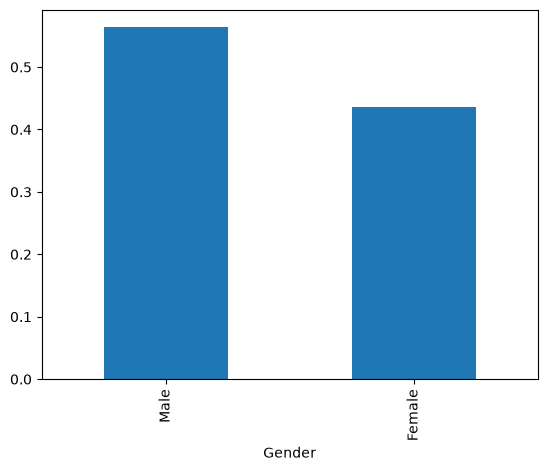

In [119]:
train["Gender"].value_counts(normalize=True).plot(kind="bar")

Gender
Female    0.280693
Male      0.159017
Name: 1, dtype: float64


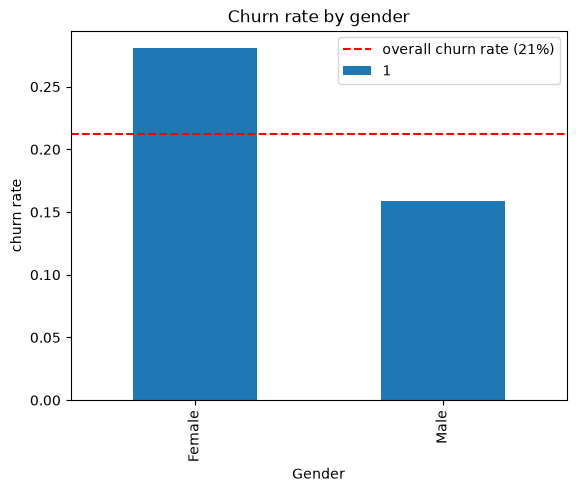

In [120]:
churn_by_gender_rate = pd.crosstab(train["Gender"], train["Exited"], normalize="index")[1]
print(churn_by_gender_rate)

churn_by_gender_rate.plot(kind="bar")
plt.axhline(train["Exited"].mean(), color="red", linestyle="--", label="overall churn rate (21%)")
plt.ylabel("churn rate")
plt.title("Churn rate by gender")
plt.legend()
plt.show()

**Observation:** 56% of customers are men, 44% women. Churn rate is **28.1% for women** and **15.9% for men** (overall 21.2%): +12.2 points for women, i.e. about 1.8 times the male churn rate.

**Hypothesis:** churn depends on gender.
- H0: `Exited` is independent of `Gender`. α = 5%.
- Test: χ² test of independence (two categorical variables).

In [121]:
churn_by_gender = pd.crosstab(train["Gender"], train["Exited"])
result = chi2_contingency(churn_by_gender)

print("p-value:", result.pvalue)
print("min expected count:", result.expected_freq.min())

# Strength of the link : Cramér's V, between 0 (no link) and 1 (perfect link)
n = churn_by_gender.values.sum()
k = min(churn_by_gender.shape)
cramers_v = np.sqrt(result.statistic / (n * (k - 1)))
print("Cramér's V:", round(cramers_v, 3))

p-value: 0.0
min expected count: 13278.86285598869
Cramér's V: 0.148


**Conclusion**
- Condition met: minimum expected count ≈ 13,279 ≥ 5.
- p < 0.001 < α: **H0 is rejected**. In this data, churn is not independent of gender.
- With 143,579 customers, even a small difference gives a tiny p-value. Strength: Cramér's V = 0.15, a weak link (benchmarks for a 2-column table: 0.1 weak, 0.3 moderate, 0.5 strong).
- **Limitation:** the test was run on the same data that suggested the hypothesis (confirmation bias).

**Ethics:** this is a description of the data. Whether `Gender` is used as a feature is decided at feature selection (see open questions in `00_framing`).

## 9. NumOfProducts

Ordered variable (1 to 4 products). Possible leakage risk (see open questions in `00_framing`).

Distribution:
NumOfProducts
1    0.469
2    0.511
3    0.017
4    0.003
Name: proportion, dtype: float64

Churn rate:
NumOfProducts
1    0.348
2    0.060
3    0.884
4    0.869
Name: 1, dtype: float64

chi2 p-value: 0 | min expected count: 86 | Cramér's V: 0.421


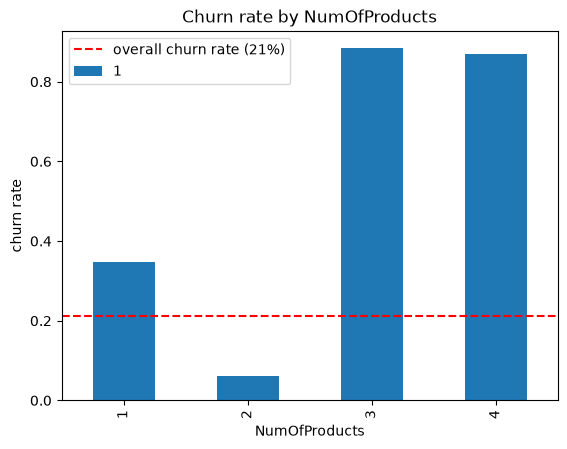

In [122]:
churn_by_category(train, "NumOfProducts")

**Observation**

| Products | Share of customers | Churn rate |
|---|---|---|
| 1 | 46.9% | 34.8% |
| 2 | 51.1% | **6.0%** |
| 3 | 1.7% | **88.4%** |
| 4 | 0.3% | **86.9%** |

- Churn **drops** from 1 to 2 products (35% → 6%), then **jumps** at 3 and 4 products (≈ 88%). The variable is ordered, but the link is **not monotonic** (U-shape). To remember for encoding: treating `NumOfProducts` as a plain number (1, 2, 3, 4) in a linear model would not capture this shape.
- χ² test: p < 0.001 (minimum expected count = 86 ≥ 5). Cramér's V = 0.42: a moderate-to-strong link, the strongest so far (country 0.21, gender 0.15).
- **Limitation:** tested on the same data that suggested the hypothesis (confirmation bias).

**Leakage check:** no global leakage (no category that covers many customers separates churners almost perfectly). Two timing scenarios, since the measurement date is unknown (see `00_framing`):
- **3–4 products (≈ 88% churn, 2% of customers):** leakage would require opening products at the time of leaving, which is implausible from a business point of view. This is more likely a real customer profile (or a pattern of the original data).
- **1 product (34.8% churn, 47% of customers):** a leaving customer often closes products one by one before closing the last account. If `NumOfProducts` was recorded late, churners would appear with fewer products than they really had, which would inflate churn at 1 product. Possible, not verifiable; this category weighs a lot, so it is the main risk to keep in mind.

## 10. HasCrCard

Binary variable (1 = has a credit card). Possible leakage risk (see open questions in `00_framing`).

Distribution:
HasCrCard
0.0    0.246
1.0    0.754
Name: proportion, dtype: float64

Churn rate:
HasCrCard
0.0    0.228
1.0    0.207
Name: 1, dtype: float64

chi2 p-value: 1.11e-17 | min expected count: 7487 | Cramér's V: 0.023


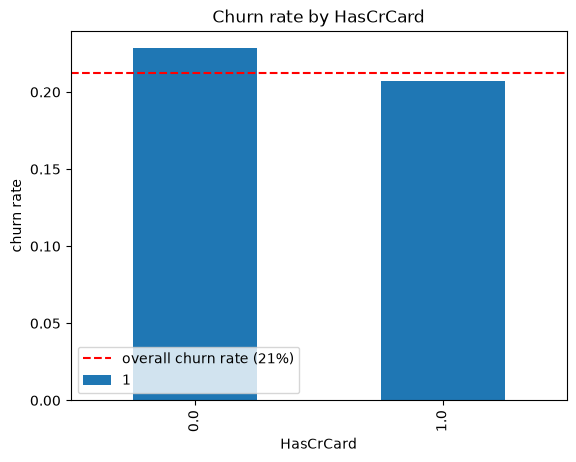

In [123]:
churn_by_category(train, "HasCrCard")

**Observation**
- 75.4% of customers have a credit card, 24.6% do not.
- Churn rates are very close: **22.8%** without a card vs **20.7%** with a card (2 points).
- χ² test: p ≈ 1e-17 (minimum expected count = 7,487 ≥ 5), so the difference is significant, but only because the sample is large. Cramér's V = 0.023 (< 0.1): the link is **negligible**.
- `HasCrCard` carries very little information about churn: to keep in mind at feature selection.

**Leakage check:** if leaving customers closed their card before closing their account, churn would be higher among customers without a card. This is the case, but the gap is only 2 points (V = 0.023): the leakage risk is negligible in practice.

## 11. IsActiveMember

Binary variable (1 = active member; "active" is not defined, see 00_framing). Possible leakage risk (see open questions in `00_framing`).

Distribution:
IsActiveMember
0.0    0.503
1.0    0.497
Name: proportion, dtype: float64

Churn rate:
IsActiveMember
0.0    0.298
1.0    0.125
Name: 1, dtype: float64

chi2 p-value: 0 | min expected count: 15128 | Cramér's V: 0.211


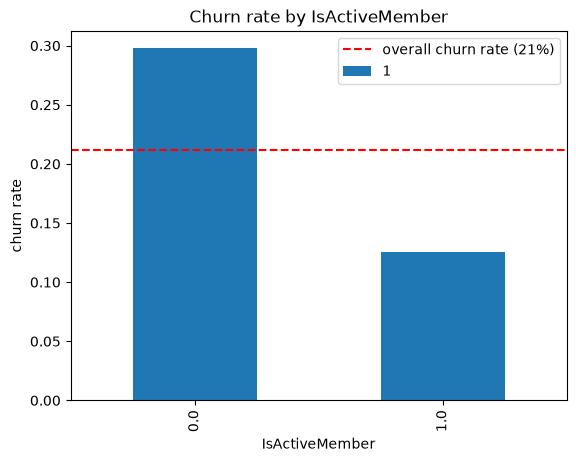

In [124]:
churn_by_category(train, "IsActiveMember")

**Observation**
- 49.7% of customers are active members, 50.3% are not.
- Churn rate is **29.8%** for inactive members vs **12.5%** for active members (+17.3 points, about 2.4 times).
- χ² test: p < 0.001 (minimum expected count = 15,128 ≥ 5). Cramér's V = 0.21: a weak-to-moderate link, at the same level as the country, stronger than `HasCrCard` (0.02) and weaker than `NumOfProducts` (0.42).

**Leakage check:** no global leakage: `IsActiveMember` does not separate churners almost perfectly (70% of inactive members did not leave). However, this is the **most serious timing risk** of the four variables: inactivity can be a direct consequence of leaving (a customer who has left is no longer active). If `IsActiveMember` was recorded at or after the churn, part of the link would be leakage. Not verifiable (measurement date and definition of "active" unknown, see `00_framing`).

## Summary: categorical variables vs churn

| Variable | Churn rate per category | Cramér's V | Link | Leakage risk |
|---|---|---|---|---|
| `NumOfProducts` | 1: 34.8% · 2: 6.0% · 3: 88.4% · 4: 86.9% | 0.42 | moderate to strong, U-shaped | possible at 1 product (gradual closing) |
| `Geography` | France 16.5% · Spain 17.3% · Germany 38.0% | 0.21 | weak to moderate | low |
| `IsActiveMember` | inactive 29.8% · active 12.5% | 0.21 | weak to moderate | **most serious** (inactivity can follow churn) |
| `Gender` | female 28.1% · male 15.9% | 0.15 | weak | low (ethical question) |
| `HasCrCard` | without 22.8% · with 20.7% | 0.02 | negligible | negligible |

All χ² tests reject independence (p < 0.001), mostly because of the sample size: Cramér's V is the relevant measure of strength. All tests were run on the same data that suggested the hypotheses (confirmation bias).

**Open question for the between-features analysis:** German customers churn about twice as much. Is it the country itself, or another variable that differs between countries?

## 12. Why do German customers churn more?

Germany has a 38% churn rate vs about 17% in France and Spain (section 7). German customers may differ on another variable linked to churn. First candidate: `NumOfProducts`, the most strongly linked variable (section 9).

In [125]:
pd.crosstab(train["Geography"], train["NumOfProducts"], normalize="index")

NumOfProducts,1,2,3,4
Geography,,,,
France,0.433713,0.550668,0.013580,0.002039
Germany,0.595250,0.370337,0.028700,0.005713
Spain,0.440959,0.540079,0.016905,0.002058


**Step 1: product mix by country.** German customers more often have a single product (59.5% vs about 44% in France and Spain) and less often two products (37.0% vs 54–55%). Since one product is linked to much higher churn than two (section 9), **part** of the German effect comes from the product mix.

In [126]:
pd.crosstab([train["NumOfProducts"], train["Geography"]], train["Exited"], normalize="index")

Exited                          0         1
NumOfProducts Geography                    
1             France     0.706406  0.293594
              Germany    0.501172  0.498828
              Spain      0.706153  0.293847
2             France     0.954781  0.045219
              Germany    0.861512  0.138488
              Spain      0.950821  0.049179
3             France     0.151079  0.848921
              Germany    0.065972  0.934028
              Spain      0.125468  0.874532
4             France     0.173653  0.826347
              Germany    0.081395  0.918605
              Spain      0.153846  0.846154

**Step 2: churn by country at equal number of products (stratified analysis).**

| Products | France | Spain | Germany |
|---|---|---|---|
| 1 | 29.4% | 29.4% | **49.9%** |
| 2 | 4.5% | 4.9% | **13.8%** |
| 3 | 84.9% | 87.5% | **93.4%** |
| 4 | 82.6% | 84.6% | **91.9%** |

- Within every product category, German customers churn more; with 2 products, about 3 times more.
- France and Spain behave almost identically in every category: Germany is the exception.

**Conclusion:** the product mix explains **part** of the higher German churn, not all of it. A German effect remains at equal number of products.

No formal test: the difference is large and consistent across all strata. Whether Germany has its own effect, once the number of products is taken into account, will be assessed at the modeling step.

**Open question:** what else differs for German customers? To check with `Balance` (section 13).

## 13. Balance

In [127]:
train["Balance"].describe()

count    143579.000000
mean      55533.640642
std       62822.616346
min           0.000000
25%           0.000000
50%           0.000000
75%      119948.090000
max      250898.090000
Name: Balance, dtype: float64

<Axes: ylabel='Frequency'>

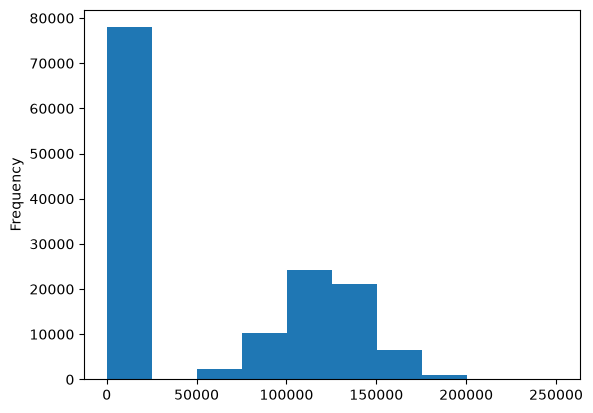

In [128]:
train["Balance"].plot(kind="hist")

**Univariate:** at least half of the customers have a zero balance (median = 0); positive balances form a bell-shaped distribution around 120,000. `Balance` therefore behaves like **two populations**: zero and positive.

**Idea (feature engineering):** a binary variable `has_balance` (1 if `Balance` > 0), studied below without modifying `train`.

Distribution:
has_balance
0    0.543
1    0.457
Name: proportion, dtype: float64

Churn rate:
has_balance
0    0.162
1    0.272
Name: 1, dtype: float64

chi2 p-value: 0 | min expected count: 13925 | Cramér's V: 0.134


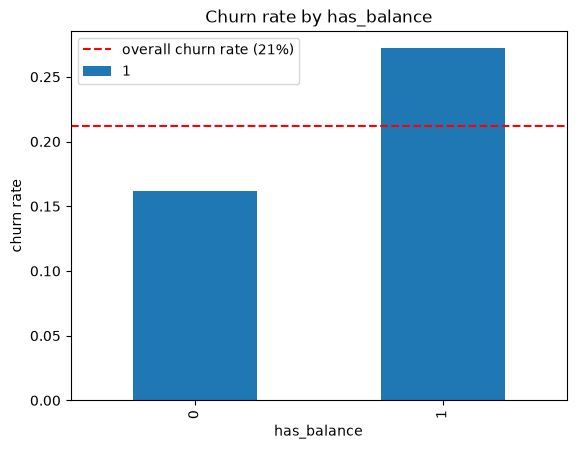

In [129]:
churn_by_category(
    train.assign(has_balance=(train["Balance"] > 0).astype(int)),
    "has_balance",
)

**Observation (`has_balance`)**
- 54.3% of customers have a zero balance.
- Churn rate is **16.2%** with a zero balance vs **27.2%** with a positive balance.
- χ² test: p < 0.001; Cramér's V = 0.13, a weak link.

**Leakage check:** the scenario "customers empty their account when they leave" would give a much **higher** churn rate for zero balances (close to 100% in the extreme case). The opposite is observed: the leakage risk on `Balance` is low.

**Hypothesis (business, not verifiable here):** customers with money in their account may have more to gain by moving to another bank (better rates, better services), while customers with nothing have little reason to switch.

### Positive balances vs churn

Does the **amount** matter, among customers with a positive balance?

In [130]:
train.query("`Balance` > 0").groupby("Exited")["Balance"].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0,47803.0,121343.899521,25541.298733,3768.69,104154.250,122359.50,138023.520,250898.09
1,17858.0,121674.440635,23686.386782,3768.69,106920.255,121874.89,135927.445,238387.56


<Axes: xlabel='Exited', ylabel='Balance'>

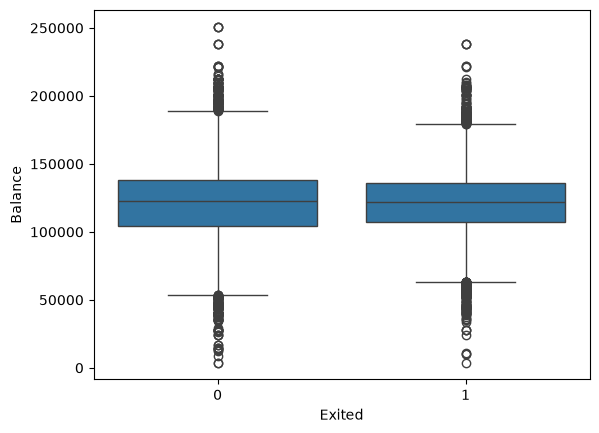

In [131]:
sns.boxplot(data=train.query("Balance > 0"), x="Exited", y="Balance")

<Axes: xlabel='Balance', ylabel='Density'>

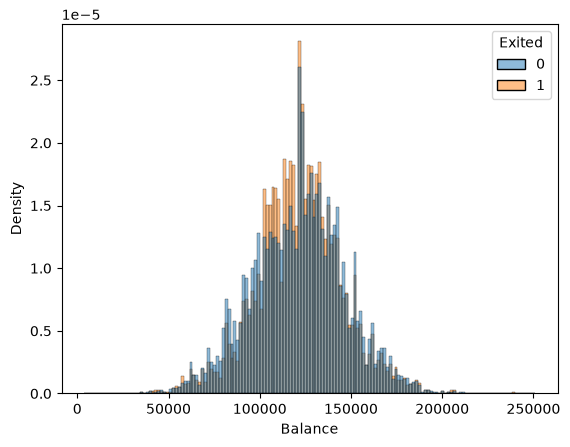

In [132]:
sns.histplot(
    data=train.query("Balance > 0"),
    x="Balance",
    hue="Exited",
    stat="density",
    common_norm=False,
)

**t-test (two independent samples)**
- H0: the mean `Balance` is the same for churners and non-churners (among positive balances). α = 5%.
- Conditions: n > 30 in each group (47,803 and 17,858) ✅; similar standard deviations (25,541 vs 23,686), so the standard t-test is acceptable ✅; i.i.d. not guaranteed (row independence red flag, see `00_framing`) ⚠️.

In [133]:
ttest_ind(train.query("Balance > 0 & Exited == 0")["Balance"] , train.query("Balance > 0 & Exited == 1")["Balance"])

TtestResult(statistic=np.float64(-1.5045290616599116), pvalue=np.float64(0.13245000626035486), df=np.float64(65659.0))

**Conclusion**
- p = 0.13 > α: **H0 is not rejected**. No evidence of a difference in mean balance between churners and non-churners (this does not prove that there is no difference).
- The means are almost identical (121,344 vs 121,674, a gap of 330), and even with 65,661 customers the test detects nothing.
- **The information in `Balance` lies in zero vs positive, not in the amount.** This supports the `has_balance` feature for feature engineering.
- **Limitation:** tested on the same data that suggested the hypothesis (confirmation bias).

### `has_balance` vs country and number of products

**Question:** can `has_balance` explain the higher German churn (section 12) and the U-shape of `NumOfProducts` (section 9)?

**Method (example: the German effect):**
1. Do German customers have a different balance status from the others? If not, the balance cannot explain why they churn more. → **χ² test** between `has_balance` and the country.
2. Comparing only customers with the **same** balance status, does Germany still churn more? → **stratified analysis**.
   - the gap disappears → the balance explains the German effect;
   - the gap shrinks → the balance explains part of it;
   - the gap stays the same → the balance does not explain it.

Same logic for the U-shape of `NumOfProducts`.

#### Step 1: is `has_balance` linked to the country and to the number of products?

In [134]:
train_bal = train.assign(has_balance=(train["Balance"] > 0).astype(int))
pd.crosstab(train_bal["Geography"], train_bal["has_balance"], normalize="index")

has_balance,0,1
Geography,,
France,0.691925,0.308075
Germany,0.003156,0.996844
Spain,0.670001,0.329999


In [135]:
pd.crosstab(train_bal["NumOfProducts"], train_bal["has_balance"], normalize="index")

has_balance,0,1
NumOfProducts,,
1,0.320691,0.679309
2,0.750481,0.249519
3,0.467331,0.532669
4,0.324257,0.675743


In [136]:
# Strength of the links between has_balance and the other two variables
for col in ["Geography", "NumOfProducts"]:
    counts = pd.crosstab(train_bal[col], train_bal["has_balance"])
    result = chi2_contingency(counts)
    n = counts.values.sum()
    k = min(counts.shape)
    cramers_v = np.sqrt(result.statistic / (n * (k - 1)))
    print(f"{col} x has_balance | p-value: {result.pvalue:.3g} | min expected count: {result.expected_freq.min():.0f} | Cramér's V: {cramers_v:.3f}")

Geography x has_balance | p-value: 0 | min expected count: 13768 | Cramér's V: 0.558
NumOfProducts x has_balance | p-value: 0 | min expected count: 185 | Cramér's V: 0.428


**Result:** yes, strongly. `has_balance` is linked to the country (χ² p < 0.001, Cramér's V = 0.56): 99.7% of German customers have a positive balance, vs about 31% in France and 33% in Spain. It is also linked to the number of products (V = 0.43): 1 product goes with positive balances (68%), 2 products with zero balances (75%).

These variables are partly redundant (to keep in mind at feature selection). Condition 1 holds: step 2 checks condition 2.

#### Step 2a: does `has_balance` explain the German effect?

Churn rate by country among customers with a positive balance only.

In [137]:
train_bal.query("has_balance == 1").groupby("Geography")["Exited"].agg(["mean", "size"])

,mean,size
Geography,,
France,0.176597,25227
Germany,0.380740,30010
Spain,0.189658,10424


**Result:** no. Among customers with a positive balance, Germany still churns much more (38.1% vs 17.7% in France and 19.0% in Spain). Neither `has_balance` nor the number of products (section 12) explains the German effect.

Germany and positive balance are almost confounded (only 0.3% of German customers have a zero balance), so their effects are hard to separate.

#### Step 2b: does `has_balance` explain the U-shape?

Churn rate by number of products, for zero and positive balances separately.

In [138]:
train_bal.groupby(["NumOfProducts", "has_balance"])["Exited"].mean().unstack()

has_balance,0,1
NumOfProducts,,
1,0.439661,0.305085
2,0.036338,0.132477
3,0.841432,0.920718
4,0.824427,0.890110


**Result:** no. Within each balance group, 1 product still churns much more than 2 products (zero balance: 44.0% vs 3.6%; positive balance: 30.5% vs 13.2%).

**Interaction:** read by row, the same table shows that the effect of the balance depends on the number of products. With 1 product, a zero balance churns **more** (44.0% vs 30.5%); with 2 products, it churns **less** (3.6% vs 13.2%). The overall result "positive balance → more churn" (section 13) hides opposite effects. A model able to capture interactions (e.g. a decision tree) could use this.

#### Conclusion

- `has_balance` explains neither the German effect nor the U-shape, but it interacts with the number of products.
- **Plausibility:** 99.7% of positive balances in Germany is implausible as a random feature of real customers. Two hypotheses, not verifiable: an artifact of how the original data was collected, or a real pattern tied to this bank (e.g. German customers using it as their main bank). In both cases, the German effect may not generalize to another bank (see red flags in `00_framing`).
- **Limitation:** all findings come from the same data that suggested them (confirmation bias).